# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** Выполнялось в Google Colab на Tesla T4 (14913 MiB), ultralytics 8.4.216, torch 2.14.1+cu130. Датасет: [Brain tumor object detection datasets (davidbroberts)](https://www.kaggle.com/datasets/davidbroberts/brain-tumor-object-detection-datasets), заявленная лицензия CC0 Public Domain. Внешние источники: семинары 5–6, [документация Ultralytics](https://docs.ultralytics.com/models/yolo26/), помощь ChatGPT в проверке кода и оформлении выводов. Бонус 6.1 не выполнялся; 6.2–6.5 выполнены. Ограничение: разбиение выполнено по строковым префиксам имён файлов; соответствие форматов ID между плоскостями не доказано (см. 2.1).

In [54]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.216, torch 2.14.1+cu130, device: Tesla T4


In [55]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [56]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def match_predictions_one_image(pred, gt, iou_thr=0.5):
    """Greedy matching within each class in descending confidence order.

    An already matched GT cannot be reused, but another free GT with sufficient
    IoU can still be matched. Returns TP flags in the original prediction order.
    """
    pb = np.asarray(pred['boxes'], dtype=np.float64).reshape(-1, 4)
    pl = np.asarray(pred['labels'], dtype=np.int64).reshape(-1)
    ps = np.asarray(pred['scores'], dtype=np.float64).reshape(-1)
    gb = np.asarray(gt['boxes'], dtype=np.float64).reshape(-1, 4)
    gl = np.asarray(gt['labels'], dtype=np.int64).reshape(-1)
    assert len(pb) == len(pl) == len(ps) and len(gb) == len(gl)
    matched = np.zeros(len(pb), dtype=bool)
    for c in np.unique(pl):
        pi = np.flatnonzero(pl == c)
        gi = np.flatnonzero(gl == c)
        if not len(gi):
            continue
        ious = box_iou(torch.as_tensor(pb[pi], dtype=torch.float32),
                       torch.as_tensor(gb[gi], dtype=torch.float32)).numpy()
        used = np.zeros(len(gi), dtype=bool)
        for local_i in np.argsort(-ps[pi], kind='stable'):
            valid = np.flatnonzero((ious[local_i] >= iou_thr) & ~used)
            if valid.size:
                local_j = valid[np.argmax(ious[local_i, valid])]
                used[local_j] = True
                matched[pi[local_i]] = True
    return matched


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # (mAP50 по классам с GT, AP50 каждого класса). All-point interpolation (VOC2010+),
    # поэтому числа могут отличаться от 101-точечной интерполяции ultralytics.
    assert len(preds) == len(gts), 'Длины preds и gts должны совпадать'
    assert n_classes > 0
    true_flags = [match_predictions_one_image(p, g, iou_thr) for p, g in zip(preds, gts)]
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g, matched in zip(preds, gts, true_flags):
            n_gt += int(np.count_nonzero(np.asarray(g['labels']) == c))
            keep = np.flatnonzero(np.asarray(p['labels']) == c)
            hits.extend((float(p['scores'][i]), bool(matched[i])) for i in keep)
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def precision_recall_at_conf(preds, gts, iou_thr=0.5):
    """Micro precision/recall именно на переданном наборе предсказаний (порог conf фиксирован)."""
    assert len(preds) == len(gts)
    tp = sum(int(match_predictions_one_image(p, g, iou_thr).sum()) for p, g in zip(preds, gts))
    n_pred = sum(len(p['labels']) for p in preds)
    n_gt = sum(len(g['labels']) for g in gts)
    return dict(tp=tp, fp=n_pred - tp, fn=n_gt - tp,
                precision=tp / n_pred if n_pred else 0.0,
                recall=tp / n_gt if n_gt else 0.0)


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out


In [57]:
# Дополнительные тесты mAP: предсказание должно иметь возможность выбрать свободный GT.
_demo_gt = [dict(boxes=np.array([[0, 0, 10, 10], [2, 0, 12, 10]], dtype=float),
                 labels=np.array([0, 0]))]
_demo_pred = [dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 11, 10]], dtype=float),
                   labels=np.array([0, 0]), scores=np.array([0.9, 0.8]))]
assert np.isclose(evaluate_map50(_demo_pred, _demo_gt, 1)[0], 1.0)
assert precision_recall_at_conf(_demo_pred, _demo_gt)['tp'] == 2
assert evaluate_map50([dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=int),
                            scores=np.zeros(0))], _demo_gt, 1)[0] == 0
assert precision_recall_at_conf([dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=int),
                                     scores=np.zeros(0))], _demo_gt)['fn'] == 2
print('mAP50 / precision-recall: дополнительные тесты пройдены')

mAP50 / precision-recall: дополнительные тесты пройдены


---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [58]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)

# параметры считаем ДО первого predict (потом Conv+BN сольются)
n_params = sum(p.numel() for p in model_coco.model.parameters())
sha = hashlib.sha256(weights_path.read_bytes()).hexdigest()

dummy = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
for _ in range(5):                                   # прогрев
    model_coco.predict(dummy, imgsz=IMGSZ, device=DEVICE, verbose=False)
lat = []
for _ in range(15):
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t0 = time.perf_counter()
    model_coco.predict(dummy, imgsz=IMGSZ, device=DEVICE, verbose=False)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    lat.append((time.perf_counter() - t0) * 1e3)

MODEL_INFO = dict(ultralytics=ultralytics.__version__, weights=Path(WEIGHTS).name,
                  sha256=sha, size_mb=weights_path.stat().st_size / 2**20,
                  params=int(n_params), n_classes_coco=len(model_coco.names),
                  latency_ms=float(np.mean(lat)))
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 11.239389466694169}

In [59]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 11.239389466694169}

**Ответ:** Использована `yolo26n.pt`: SHA256 `9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef`, 5.29 МиБ, 2 572 280 параметров до fusion, 80 классов COCO; среднее время полного predict на T4 при 640×640 — 11.24 мс. По [официальной таблице](https://docs.ultralytics.com/models/yolo26/) YOLO26n и YOLO26s имеют соответственно 2.4 и 9.5 млн параметров после fusion, COCO val mAP50-95 40.9% и 48.6% (40.1% и 47.8% в e2e), T4 TensorRT10 1.7 и 2.5 мс; это другой режим замера, не равный нашему predict. Nano выбрана ради меньших затрат памяти и времени. Код и веса Ultralytics предлагаются по AGPL-3.0 либо коммерческой лицензии; AGPL требует соблюдения условий распространения и предоставления соответствующего исходного кода, в том числе для модифицированной программы при взаимодействии с ней по сети.

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [60]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    # ваш код
    counts = dict(backbone=0, neck=0, head=0)
    for i, layer in enumerate(layers):
        n = sum(p.numel() for p in layer.parameters())
        key = 'backbone' if i < n_backbone else ('head' if i == len(layers) - 1 else 'neck')
        counts[key] += n
    return counts


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    # ваш код
    captured = []
    def hook(module, args):
        captured.extend(tuple(t.shape) for t in args[0])
    h = det_model.model[-1].register_forward_pre_hook(hook)
    was_training = det_model.training
    det_model.eval()
    device = next(det_model.parameters()).device
    with torch.no_grad():
        out = det_model(torch.zeros(1, 3, imgsz, imgsz, device=device))
    h.remove()
    det_model.train(was_training)
    return captured, out


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [61]:
arch = YOLO(WEIGHTS).model
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [62]:
print('выход модели:', shapes(out))
total = sum(blocks.values())
for k, v in blocks.items():
    print(f'{k}: {v:,} ({v / total:.1%})')

выход модели: [(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]
backbone: 1,365,472 (53.1%)
neck: 897,152 (34.9%)
head: 309,656 (12.0%)


**Ответ:** `Backbone` (53.1% параметров) извлекает признаки и выдает карты `P3`, `P4`, `P5` со страйдами 8, 16, 32. `Neck` (34.9%, PAN-FPN) объединяет эти масштабы путями сверху вниз и снизу вверх, чтобы мелкие объекты получали семантику глубоких слоев, а крупные - детали. `Head` (12.0%) в каждой точке карты предсказывает 4 координаты бокса и score по классам. Детектор anchor-free: бокс регрессируется как смещение от точки сетки, без заранее заданных anchor-боксов. Число 8400 = $80^2 + 40^2 + 20^2$ (сумма точек трех карт при входе 640). Число 84 = 4 координаты + 80 классов COCO. Ветка `one2many` используется для обучения (TAL-assignment, несколько предсказаний на объект), а `one2one` - для инференса (end-to-end, одно предсказание на объект), поэтому YOLO26 обходится без NMS (в нем также убран DFL).

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [63]:
KAGGLE_INPUT = Path('/kaggle/input/brain-tumor-object-detection-datasets')
if KAGGLE_INPUT.exists():
    RAW = KAGGLE_INPUT
else:
    if importlib.util.find_spec('kagglehub') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'], check=True)
    import kagglehub
    RAW = Path(kagglehub.dataset_download('davidbroberts/brain-tumor-object-detection-datasets'))
print(RAW, sorted(p.name for p in RAW.iterdir()))

/kaggle/input/brain-tumor-object-detection-datasets ['axial_t1wce_2_class', 'coronal_t1wce_2_class', 'sagittal_t1wce_2_class']


In [ ]:
import re
import yaml
from sklearn.model_selection import GroupShuffleSplit
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}


def patient_key(r):
    stem = Path(r['image']).stem
    match = re.match(r'^(\d+)(?=[_\s(]|$)', stem)
    if match is None:
        raise ValueError(f'Не могу извлечь ID пациента из {stem!r}; проверьте формат имён')
    return match.group(1)


plane_dirs = sorted(p for p in RAW.rglob('*') if p.is_dir() and p.name.endswith('_t1wce_2_class'))
assert plane_dirs, f'под {RAW} нет папок *_t1wce_2_class — проверьте путь/распаковку'
meta = yaml.safe_load(next(plane_dirs[0].glob('*.yaml')).read_text())
names = meta['names']
CLASSES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)
DATASET_NAME = ('Brain tumor object detection datasets (davidbroberts), '
                'https://www.kaggle.com/datasets/davidbroberts/brain-tumor-object-detection-datasets, CC0 Public Domain')

n_clipped = n_dropped = n_empty = n_nolabel = 0
all_recs = []
for pd in plane_dirs:
    plane = pd.name
    img_root, lbl_root = pd / 'images', pd / 'labels'
    lab_by_key = {}
    for t in sorted(lbl_root.rglob('*.txt')):
        lab_by_key[t.relative_to(lbl_root).with_suffix('').as_posix()] = t
        lab_by_key.setdefault(t.stem, t)
    imgs = sorted(p for p in img_root.rglob('*') if p.suffix.lower() in IMG_EXT)
    print(f'{plane}: {len(imgs)} картинок')
    for ip in imgs:
        key = ip.relative_to(img_root).with_suffix('').as_posix()
        txt = lab_by_key.get(key, lab_by_key.get(ip.stem))
        if txt is None:
            n_nolabel += 1
        with Image.open(ip) as im:
            W, H = im.size
        boxes, labels = [], []
        for line in (txt.read_text().splitlines() if txt else []):
            if not line.strip():
                continue
            c, cx, cy, bw, bh = map(float, line.split())
            x1, y1, x2, y2 = (cx - bw / 2) * W, (cy - bh / 2) * H, (cx + bw / 2) * W, (cy + bh / 2) * H
            cx1, cy1, cx2, cy2 = np.clip([x1, y1, x2, y2], 0, [W, H, W, H])
            if [cx1, cy1, cx2, cy2] != [x1, y1, x2, y2]:
                n_clipped += 1
            if cx2 <= cx1 or cy2 <= cy1:
                n_dropped += 1
                continue
            boxes.append([cx1, cy1, cx2, cy2])
            labels.append(int(c))
        boxes = np.array(boxes, dtype=np.float64).reshape(-1, 4)
        labels = np.array(labels, dtype=np.int64)
        if len(boxes) == 0:
            n_empty += 1
        all_recs.append(dict(image=ip, plane=plane, width=W, height=H, boxes=boxes, labels=labels,
                             name=f"{plane.split('_')[0]}_{ip.parent.name}_{ip.name}"))

assert all_recs, 'картинки не найдены — проверьте путь и содержимое RAW'

groups = np.array([patient_key(r) for r in all_recs])
plane_names = sorted({r['plane'] for r in all_recs})
strata = np.array([[int(r['plane'] == plane) for plane in plane_names] +
                   [int(np.count_nonzero(r['labels'] == c)) for c in range(len(CLASSES))]
                   for r in all_recs], dtype=float)
all_indices = np.arange(len(all_recs))
fractions = {'train': 0.70, 'val': 0.15, 'test': 0.15}


def split_balance_score(idx_by_split):
    score = 0.0
    full = strata.sum(axis=0)
    for split, idx in idx_by_split.items():
        expected = fractions[split]
        score += ((len(idx) / len(all_recs) - expected) / expected) ** 2
        got = strata[idx].sum(axis=0) / np.maximum(full, 1)
        score += 0.25 * np.square((got - expected) / expected).mean()
    return float(score)


best_split, best_score = None, float('inf')
for attempt in range(100):
    first = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED + attempt)
    i_train, i_hold = next(first.split(all_indices, groups=groups))
    second = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED + 10000 + attempt)
    j_val, j_test = next(second.split(i_hold, groups=groups[i_hold]))
    idx_by_split = dict(train=i_train, val=i_hold[j_val], test=i_hold[j_test])
    if any(len(ids) == 0 for ids in idx_by_split.values()):
        continue
    score = split_balance_score(idx_by_split)
    if score < best_score:
        best_split, best_score = idx_by_split, score
assert best_split is not None, 'Не удалось сделать групповое разбиение'
records = {split: [all_recs[int(i)] for i in ids] for split, ids in best_split.items()}
patients_by_split = {s: {patient_key(r) for r in recs} for s, recs in records.items()}
assert not (patients_by_split['train'] & patients_by_split['val'])
assert not (patients_by_split['train'] & patients_by_split['test'])
assert not (patients_by_split['val'] & patients_by_split['test'])
assert sum(map(len, records.values())) == len(all_recs)

print('Групповой сплит по ID пациента:', {s: len(rs) for s, rs in records.items()})
print('Число пациентов:', {s: len(ids) for s, ids in patients_by_split.items()})
print(f'обрезано: {n_clipped}, вырожденных: {n_dropped}, без объектов: {n_empty}, без txt-файла: {n_nolabel}')
print('объектов по классам:', Counter(CLASSES[int(l)] for r in all_recs for l in r['labels']))
print('примеры имён:', [r['name'] for r in all_recs[:3]])


axial_t1wce_2_class: 385 картинок
coronal_t1wce_2_class: 397 картинок
sagittal_t1wce_2_class: 334 картинок
Групповой сплит по ID пациента: {'train': 778, 'val': 172, 'test': 166}
Число пациентов: {'train': 168, 'val': 36, 'test': 37}
обрезано: 0, вырожденных: 0, без объектов: 15, без txt-файла: 15
объектов по классам: Counter({'negative': 591, 'positive': 575})
примеры имён: ['axial_test_00018_101.jpg', 'axial_test_00018_109.jpg', 'axial_test_00018_111.jpg']


In [23]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 778, 'val': 172, 'test': 166}

train 778 картинок; {'negative': 411, 'positive': 405}
val 172 картинок; {'negative': 95, 'positive': 87}
test 166 картинок; {'negative': 85, 'positive': 83}


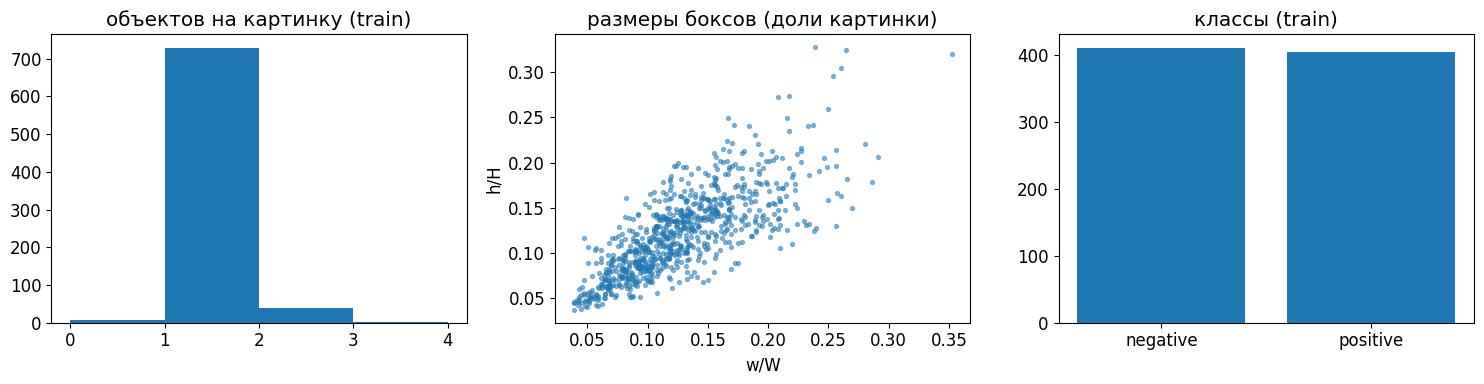

медианная площадь бокса, доля картинки: 0.014528774498999995


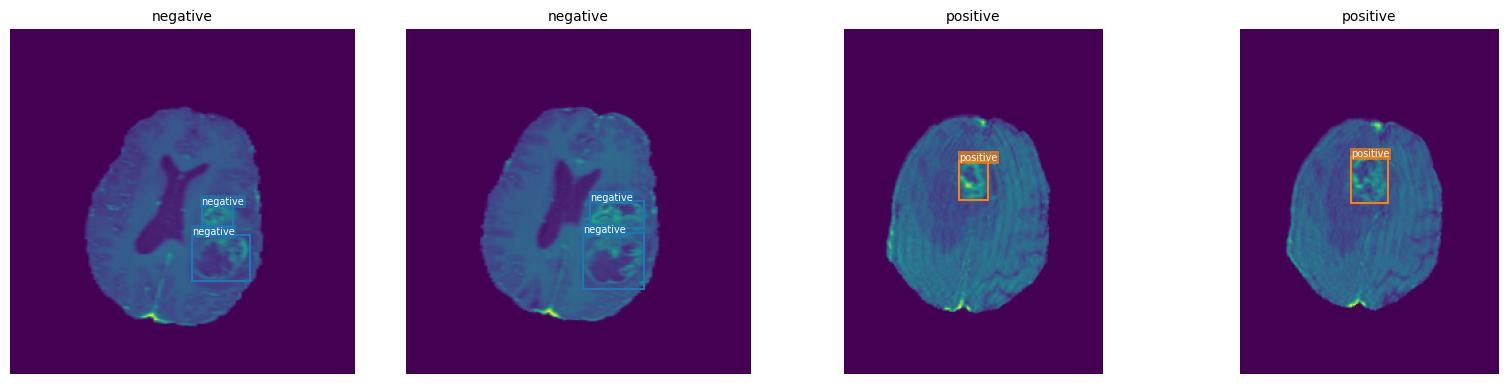

In [24]:
for split, recs in records.items():
    cnt = Counter(int(l) for r in recs for l in r['labels'])
    print(split, len(recs), 'картинок;', {CLASSES[c]: cnt.get(c, 0) for c in range(len(CLASSES))})

n_per_img = [len(r['labels']) for r in records['train']]
rel_wh = np.concatenate([np.stack([(r['boxes'][:, 2] - r['boxes'][:, 0]) / r['width'],
                                   (r['boxes'][:, 3] - r['boxes'][:, 1]) / r['height']], 1)
                         for r in records['train'] if len(r['boxes'])])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(n_per_img, bins=range(max(n_per_img) + 2)); axes[0].set_title('объектов на картинку (train)')
axes[1].scatter(rel_wh[:, 0], rel_wh[:, 1], s=8, alpha=0.5)
axes[1].set_xlabel('w/W'); axes[1].set_ylabel('h/H'); axes[1].set_title('размеры боксов (доли картинки)')
axes[2].bar(CLASSES, [sum(int(l) == c for r in records['train'] for l in r['labels']) for c in range(len(CLASSES))])
axes[2].set_title('классы (train)')
plt.tight_layout(); plt.show()
print('медианная площадь бокса, доля картинки:', float(np.median(rel_wh[:, 0] * rel_wh[:, 1])))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for c in range(len(CLASSES)):
    ex = [r for r in records['train'] if c in r['labels']][:2]
    for ax, r in zip(axes[2 * c:2 * c + 2], ex):
        draw_boxes(ax, np.array(Image.open(r['image'])), r['boxes'], r['labels'], CLASSES, title=CLASSES[c])
plt.tight_layout(); plt.show()

In [25]:
pat = {s: {patient_key(r) for r in recs} for s, recs in records.items()}
print('Уникальных пациентов всего:', len(set().union(*pat.values())))
print('по сплитам:', {s: len(v) for s, v in pat.items()})
intersections = {
    'train∩val': len(pat['train'] & pat['val']),
    'train∩test': len(pat['train'] & pat['test']),
    'val∩test': len(pat['val'] & pat['test']),
}
print('пересечения пациентов:', intersections)
assert all(v == 0 for v in intersections.values()), 'Обнаружена утечка пациентов между сплитами'
for split, recs in records.items():
    by_plane = Counter(r['plane'].split('_')[0] for r in recs)
    by_class = Counter(CLASSES[int(l)] for r in recs for l in r['labels'])
    print(split, 'изображения:', len(recs), 'по плоскостям:', dict(by_plane), 'метки:', dict(by_class))
unique_names = Counter(f"{r['plane'].split('_')[0]}_{Path(r['image']).name}" for r in all_recs)
assert all(v == 1 for v in unique_names.values()), 'Коллизия имён файлов при экспорте'


Уникальных пациентов всего: 241
по сплитам: {'train': 168, 'val': 36, 'test': 37}
пересечения пациентов: {'train∩val': 0, 'train∩test': 0, 'val∩test': 0}
train изображения: 778 по плоскостям: {'axial': 257, 'coronal': 292, 'sagittal': 229} метки: {'negative': 411, 'positive': 405}
val изображения: 172 по плоскостям: {'axial': 66, 'coronal': 53, 'sagittal': 53} метки: {'negative': 95, 'positive': 87}
test изображения: 166 по плоскостям: {'axial': 62, 'coronal': 52, 'sagittal': 52} метки: {'negative': 85, 'positive': 83}


**Ответ:** Использованы 1116 T1wCE-снимков RSNA-MICCAI из трёх плоскостей: 385 axial, 397 coronal, 334 sagittal. Всего 1166 боксов (591 `negative`, 575 `positive`), классы почти сбалансированы. Метки относятся к размеченным областям опухоли; связь с MGMT-статусом следует из контекста исходного конкурса, но точное соответствие меток статусу в данной выгрузке не проверено. Медианная площадь бокса — 1.45% изображения, то есть типичный объект небольшой. 15 изображений не имеют txt-разметки и трактуются как фон; это допущение, поскольку отсутствие файла не гарантирует отсутствие объекта. В сплитах train/val/test 778/172/166 изображений, 168/36/37 строковых групп, пересечения строковых ключей равны нулю. Однако `00066` и `66` считаются разными ключами: при приведении цифровых префиксов к целым числам в экспортированном наборе обнаруживаются 13/7/2 общих числовых ключей для train–val/train–test/val–test. Не установлено, обозначают ли они одних пациентов во всех плоскостях, поэтому полное отсутствие пациентской утечки не доказано. Для строгой проверки требуется таблица соответствия исходным ID или консервативное разбиение по нормализованному префиксу с повторным обучением. Данные не переименовывались в исходном датасете.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [26]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    # ваш код
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    labels = np.asarray(labels).reshape(-1)
    if len(boxes) == 0:
        return ''
    cx = (boxes[:, 0] + boxes[:, 2]) / 2 / width
    cy = (boxes[:, 1] + boxes[:, 3]) / 2 / height
    w = (boxes[:, 2] - boxes[:, 0]) / width
    h = (boxes[:, 3] - boxes[:, 1]) / height
    return ''.join(f'{int(c)} {x:.6f} {y:.6f} {bw:.6f} {bh:.6f}\n'
                   for c, x, y, bw, bh in zip(labels, cx, cy, w, h))


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    # ваш код
    rows = [ln.split() for ln in text.strip().splitlines() if ln.strip()]
    if not rows:
        return np.zeros((0, 4), dtype=np.float32), np.zeros(0, dtype=np.int64)
    a = np.array([[float(v) for v in r] for r in rows], dtype=np.float64)
    cx, cy, bw, bh = a[:, 1] * width, a[:, 2] * height, a[:, 3] * width, a[:, 4] * height
    boxes = np.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], 1).astype(np.float32)
    return boxes, a[:, 0].astype(np.int64)

In [27]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [28]:
def yolo_name(r):
    return f"{r['plane'].split('_')[0]}_{Path(r['image']).name}"

In [29]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    # ваш код
    idir, ldir = YOLO_ROOT / 'images' / split, YOLO_ROOT / 'labels' / split
    idir.mkdir(parents=True, exist_ok=True); ldir.mkdir(parents=True, exist_ok=True)
    for r in recs:
        name = yolo_name(r)
        shutil.copy(r['image'], idir / name)
        (ldir / (Path(name).stem + '.txt')).write_text(to_yolo(r['boxes'], r['labels'], r['width'], r['height']))


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'
print(DATA_YAML.read_text())

path: /content/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: negative
  1: positive



round-trip YOLO txt: max ошибка, px = 1.5212890616567165e-05
YOLO -> COCO -> YOLO: ok


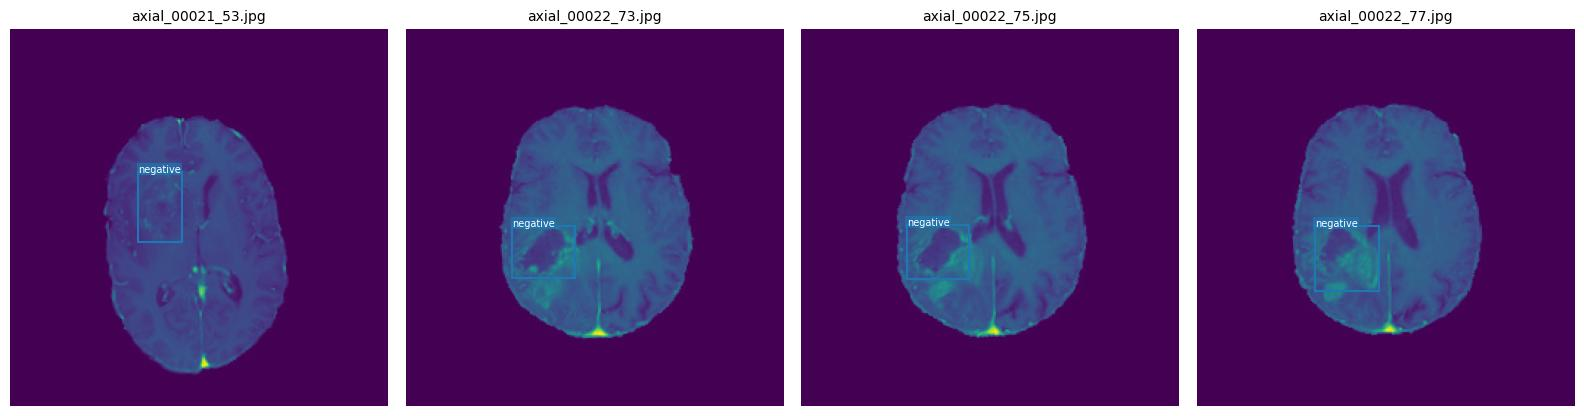

In [30]:
max_err = 0.0
for split, recs in splits.items():
    for r in recs:
        b, l = from_yolo((YOLO_ROOT / 'labels' / split / (Path(yolo_name(r)).stem + '.txt')).read_text(),
                         r['width'], r['height'])
        assert (l == r['labels']).all() and b.shape == r['boxes'].shape
        if len(b): max_err = max(max_err, float(np.abs(b - r['boxes']).max()))
print('round-trip YOLO txt: max ошибка, px =', max_err)


def to_coco(recs, classes):
    images, anns, aid = [], [], 1
    for iid, r in enumerate(recs, 1):
        images.append(dict(id=iid, file_name=yolo_name(r), width=int(r['width']), height=int(r['height'])))
        for (x1, y1, x2, y2), lab in zip(r['boxes'], r['labels']):
            anns.append(dict(id=aid, image_id=iid, category_id=int(lab), iscrowd=0,
                             bbox=[float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                             area=float((x2 - x1) * (y2 - y1))))
            aid += 1
    return dict(images=images, annotations=anns, categories=[dict(id=i, name=n) for i, n in enumerate(classes)])


def from_coco(coco):
    by_img = {im['id']: [] for im in coco['images']}
    for a in coco['annotations']:
        x, y, w, h = a['bbox']
        by_img[a['image_id']].append((x, y, x + w, y + h, a['category_id']))
    out = []
    for im in coco['images']:
        rows = by_img[im['id']]
        out.append(dict(image=im['file_name'], width=im['width'], height=im['height'],
                        boxes=np.array([r[:4] for r in rows], dtype=np.float32).reshape(-1, 4),
                        labels=np.array([r[4] for r in rows], dtype=np.int64)))
    return out


for split, recs in splits.items():
    for r, r2 in zip(recs, from_coco(to_coco(recs, CLASSES))):
        assert np.allclose(r['boxes'], r2['boxes'], atol=1e-3) and (r['labels'] == r2['labels']).all()
print('YOLO -> COCO -> YOLO: ok')

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, r in zip(axes, [r for r in records['val'] if len(r['boxes'])][:4]):
    name = yolo_name(r)
    b, l = from_yolo((YOLO_ROOT / 'labels' / 'val' / (Path(name).stem + '.txt')).read_text(), r['width'], r['height'])
    draw_boxes(ax, np.array(Image.open(YOLO_ROOT / 'images' / 'val' / name)), b, l, CLASSES, title=name)
plt.tight_layout(); plt.show()

**Ответ:** `Round-trip` через `txt` дает максимальную ошибку ~1.5e-5 px (из-за округления до 6 знаков и `float32`), конвертация `YOLO` $\rightarrow$ `COCO` $\rightarrow$ `YOLO` совпадает по боксам и меткам на всех 1116 картинках. Тест ловит перепутанные оси x/y, ненормированные координаты, ошибку "центр $\leftrightarrow$ углы", потерю объектов и сдвиг индекса класса. Он не ловит ошибки, симметричные в `to_yolo` и `from_yolo` (если обе функции неправы одинаково), неверное соответствие "файл картинки $\leftrightarrow$ файл разметки" и ошибки в самой исходной разметке. Визуальная проверка (4 снимка val) подтверждает, что оси не зеркальны, а боксы корректно охватывают целевые области.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

coco_map50 = 0.0
что COCO вообще предсказывает: Counter({'donut': 84, 'bird': 67, 'person': 50, 'teddy bear': 41, 'cat': 9, 'tie': 9, 'bear': 4, 'dog': 3, 'vase': 3, 'cake': 3, 'clock': 3, 'elephant': 2, 'dining table': 2, 'bed': 2, 'toothbrush': 1, 'snowboard': 1, 'mouse': 1, 'remote': 1})


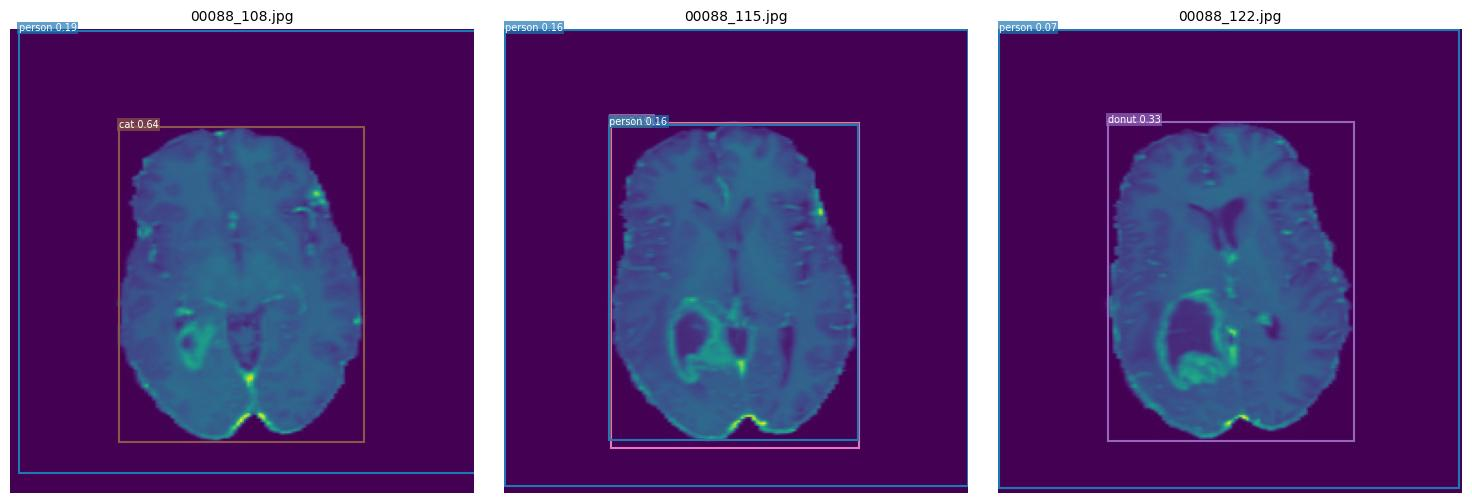

In [31]:
coco_preds = predict_records(model_coco, records[FINAL_SPLIT], conf=0.05)
COCO_TO_OURS = {} # опухоли/МРТ среди 80 классов COCO нет
mapped = []
for p in coco_preds:
    keep = np.array([model_coco.names[int(c)] in COCO_TO_OURS for c in p['labels']], dtype=bool)
    mapped.append(dict(boxes=p['boxes'][keep], scores=p['scores'][keep],
                       labels=np.array([COCO_TO_OURS[model_coco.names[int(c)]] for c in p['labels'][keep]],
                                       dtype=np.int64)))
coco_map50, _ = evaluate_map50(mapped, records[FINAL_SPLIT], len(CLASSES))
print('coco_map50 =', coco_map50)
print('что COCO вообще предсказывает:', Counter(model_coco.names[int(c)] for p in coco_preds for c in p['labels']))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, r, p in zip(axes, records[FINAL_SPLIT][:3], coco_preds[:3]):
    draw_boxes(ax, np.array(Image.open(r['image'])), p['boxes'], p['labels'], model_coco.names,
               scores=p['scores'], title=Path(r['image']).name)
plt.tight_layout(); plt.show()

In [32]:
HEUR_PARAMS = dict(q=0.97, min_frac=0.002, max_frac=0.15, erode=3, label=0)

In [33]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    # ваш код
    img = np.asarray(Image.open(image_path).convert('L'), dtype=np.float32) / 255.0
    H, W = img.shape
    empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
    lab_fg, n = ndimage.label(img > 0.12) # отделяем голову от черного фона
    if n == 0: return empty
    sizes = ndimage.sum(img > 0.12, lab_fg, range(1, n + 1))
    brain = ndimage.binary_erosion(lab_fg == int(np.argmax(sizes)) + 1, iterations=HEUR_PARAMS['erode'])
    if not brain.any(): return empty
    thr = np.quantile(img[brain], HEUR_PARAMS['q']) # яркие пятна внутри головы
    mask = ndimage.binary_opening((img >= thr) & brain, iterations=1)
    lab, n = ndimage.label(mask)
    boxes, scores = [], []
    for i, sl in enumerate(ndimage.find_objects(lab), 1):
        if sl is None: continue
        comp = lab[sl] == i
        area = int(comp.sum())
        if not (HEUR_PARAMS['min_frac'] * H * W <= area <= HEUR_PARAMS['max_frac'] * H * W): continue
        boxes.append([sl[1].start, sl[0].start, sl[1].stop, sl[0].stop])
        scores.append(float(img[sl][comp].mean()))
    return dict(boxes=np.array(boxes, dtype=float).reshape(-1, 4), scores=np.array(scores),
                labels=np.full(len(boxes), HEUR_PARAMS['label'], dtype=np.int64))

In [34]:
# ваш код: параметры эвристики, если нужны (подбирать по train, не по val)
tune_recs = [r for r in records['train'] if len(r['boxes'])][:40]
majority = Counter(int(l) for r in records['train'] for l in r['labels']).most_common(1)[0][0]
best_cfg = (-1.0, None)
for q in (0.90, 0.95, 0.97, 0.99):
    for min_frac in (0.001, 0.003, 0.01):
        HEUR_PARAMS.update(q=q, min_frac=min_frac, label=majority)
        m, _ = evaluate_map50([heuristic_detect(r['image']) for r in tune_recs], tune_recs, len(CLASSES))
        if m > best_cfg[0]: best_cfg = (m, dict(HEUR_PARAMS))
HEUR_PARAMS = best_cfg[1]
print('параметры эвристики (по train):', HEUR_PARAMS, 'mAP50 на train-подмножестве:', round(best_cfg[0], 4))

параметры эвристики (по train): {'q': 0.9, 'min_frac': 0.003, 'max_frac': 0.15, 'erode': 3, 'label': 0} mAP50 на train-подмножестве: 0.2673


In [35]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.11683695264743123,
 'heuristic_ap50_per_class': {'negative': 0.23367390529486246,
  'positive': 0.0}}

**Ответ:** В COCO нет классов этого датасета, поэтому mAP50 после сопоставления классов равен 0; на МРТ детектор часто предсказывал `donut` (84), `bird` (67), `person` (50). Яркостная эвристика использует порог интенсивности и связные компоненты; параметры выбраны по train (q=0.90, min_frac=0.003, max_frac=0.15, erode=3). На test mAP50=0.1168, AP50 negative=0.2337, positive=0: эвристика присваивает всем боксам один класс, поэтому второй класс не находит, а яркие анатомические структуры могут быть ложными детекциями.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [36]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [37]:
# ваш код
TRAIN_ARGS = dict(
    epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    optimizer='AdamW', lr0=0.001, weight_decay=0.0005, cos_lr=True,
    warmup_epochs=3, patience=20, seed=SEED, pretrained=True,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.4,   # МРТ серые: hue/saturation бессмысленны, яркость варьируется
    fliplr=0.5, flipud=0.0,            # мозг почти симметричен слева-направо; верх-низ ломает анатомию
    degrees=10, translate=0.1, scale=0.5, shear=0.0,
    mosaic=1.0, close_mosaic=10,       # мозаика помогает на маленьком датасете, в конце выключаем
    plots=True, val=True,
)

model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW,

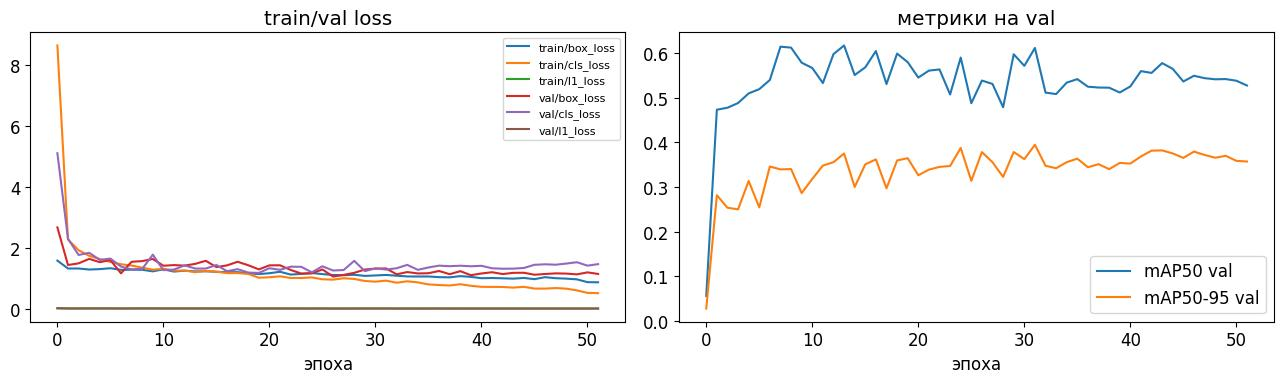

обучение: 760 s на Tesla T4, эпох: 52


In [38]:
res = read_results(run_dir)
loss_cols = [k for k in res if 'loss' in k]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k in loss_cols: axes[0].plot(res[k], label=k)
axes[0].set_xlabel('эпоха'); axes[0].legend(fontsize=8); axes[0].set_title('train/val loss')
axes[1].plot(res['metrics/mAP50(B)'], label='mAP50 val')
axes[1].plot(res['metrics/mAP50-95(B)'], label='mAP50-95 val')
axes[1].set_xlabel('эпоха'); axes[1].legend(); axes[1].set_title('метрики на val')
plt.tight_layout(); plt.show()
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, эпох: {len(res["epoch"])}')

In [39]:
fit = 0.1 * res['metrics/mAP50(B)'] + 0.9 * res['metrics/mAP50-95(B)']
print('лучшая эпоха по fitness:', int(res['epoch'][np.argmax(fit)]),
      '| максимум val mAP50:', round(float(res['metrics/mAP50(B)'].max()), 3),
      'на эпохе', int(res['epoch'][np.argmax(res['metrics/mAP50(B)'])]))
for k in loss_cols:
    v = res[k]
    print(f'{k}: первая {v[0]:.3f} → последняя {v[-1]:.3f}, минимум {v.min():.3f} (эпоха {int(res["epoch"][np.argmin(v)])})')

лучшая эпоха по fitness: 32 | максимум val mAP50: 0.617 на эпохе 14
train/box_loss: первая 1.580 → последняя 0.868, минимум 0.868 (эпоха 52)
train/cls_loss: первая 8.643 → последняя 0.510, минимум 0.510 (эпоха 52)
train/l1_loss: первая 0.009 → последняя 0.006, минимум 0.005 (эпоха 46)
val/box_loss: первая 2.670 → последняя 1.142, минимум 1.055 (эпоха 27)
val/cls_loss: первая 5.107 → последняя 1.464, минимум 1.176 (эпоха 20)
val/l1_loss: первая 0.021 → последняя 0.007, минимум 0.007 (эпоха 27)


**Ответ:** `imgsz=640`, `batch=16`, AdamW (`lr0=1e-3`, cosine decay, `warmup=3`, `patience=20`). Для МРТ отключены цветовой тон и насыщенность, оставлены изменения яркости, горизонтальное отражение, небольшие повороты и mosaic. Обучение заняло 760 с на T4 и остановилось после 52 эпох; максимум val mAP50=0.617 на эпохе 14, лучшая эпоха по рассчитанному fitness — 32. Train box loss снизился с 1.580 до 0.868, train cls loss с 8.643 до 0.510, тогда как val cls loss достиг минимума 1.176 на эпохе 20 и вырос до 1.464: это признаки переобучения, для ограничения которого применена ранняя остановка.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [40]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, data_yaml=None, **kw):
    return model.val(data=str(data_yaml if data_yaml is not None else DATA_YAML), split=split,
                     imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True,
                     verbose=False, **kw)


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 375.9±171.7 MB/s, size: 11.2 KB)
val: Scanning /content/data/yolo/labels/val.cache... 172 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 172/172 42.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 4.1it/s 2.7s
                   all        172        182      0.524      0.717      0.611      0.394
Speed: 2.2ms preprocess, 4.5ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/runs_hw2/val_best
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 452.2±290.2 MB/s, size: 11.7 KB)
val: Scanning /content/dat

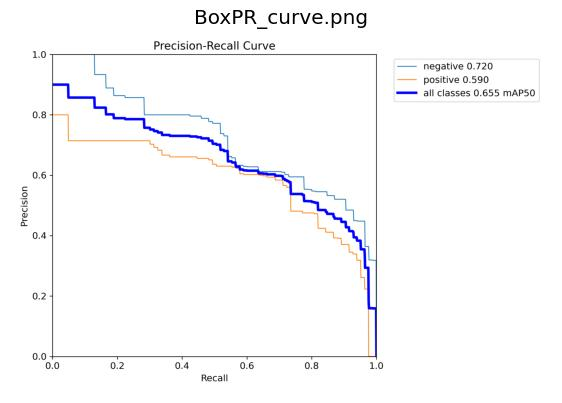

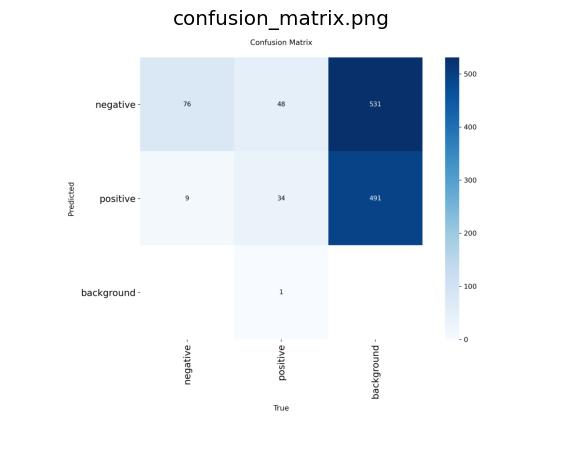

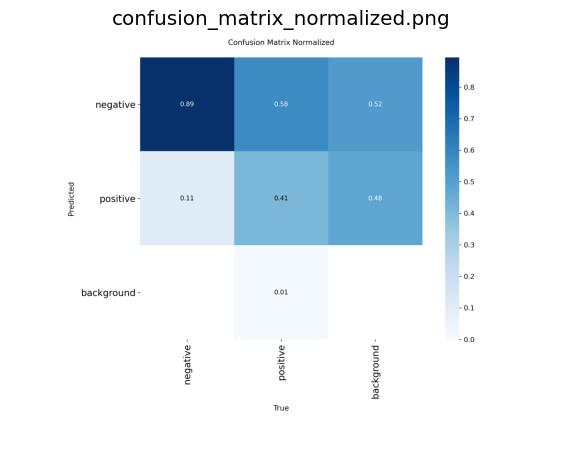

mAP50: ultralytics=0.6551, мой evaluate_map50=0.5610, AP50 по классам: [0.7025553715749607, 0.41944707250853797]
Примечание: самописный AP — all-point, Ultralytics — интерполяция по кривой; строгое совпадение не ожидается, значительный разрыв нужно расследовать.


In [41]:
# Метрики для одного и того же режима model.val и predict_records (nms=None — дефолт).
res_val = val_metrics(best, 'val', 'val_best', nms=None)
res_final = val_metrics(best, FINAL_SPLIT, f'{FINAL_SPLIT}_best', nms=None) if FINAL_SPLIT != 'val' else res_val
b = res_final.box
FINAL = dict(split=FINAL_SPLIT, map50=float(b.map50), map50_95=float(b.map),
             precision=float(b.mp), recall=float(b.mr),
             per_class={res_final.names[int(c)]: dict(ap50=float(b.ap50[i]), ap50_95=float(b.ap[i]),
                        precision=float(b.p[i]), recall=float(b.r[i]))
                        for i, c in enumerate(b.ap_class_index)})
print('val:', float(res_val.box.map50), float(res_val.box.map))
print('test/FINAL:', {k: v for k, v in FINAL.items() if k != 'per_class'})
for c, d in FINAL['per_class'].items():
    print(c, {k: round(v, 3) for k, v in d.items()})
for f in ('BoxPR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png'):
    p = Path(res_final.save_dir) / f
    if p.exists():
        plt.figure(figsize=(7, 6)); plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(f); plt.show()

preds = predict_records(best, records[FINAL_SPLIT], conf=0.001, nms=None)
my_map50, my_aps = evaluate_map50(preds, records[FINAL_SPLIT], len(CLASSES))
print(f'mAP50: ultralytics={FINAL["map50"]:.4f}, мой evaluate_map50={my_map50:.4f}, AP50 по классам: {my_aps}')
print('Примечание: самописный AP — all-point, Ultralytics — интерполяция по кривой;'
      ' строгое совпадение не ожидается, значительный разрыв нужно расследовать.')


In [42]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'split': 'test',
 'map50': 0.6551,
 'map50_95': 0.4299,
 'precision': 0.5134,
 'recall': 0.8081}

**Ответ:** На val mAP50=0.6111, mAP50-95=0.3942; на test — 0.6551 и 0.4299, precision=0.5134, recall=0.8081. AP50 классов `negative`/`positive` — 0.7204/0.5897, recall — 0.9294/0.6867 соответственно, то есть второй класс обнаруживается хуже. mAP50-95 ниже из-за более строгих требований к локализации. Самописный mAP50=0.5610 (AP 0.7026/0.4194), расхождение со стандартной оценкой составляет 0.0941: разные правила сопоставления, интерполяция и возможные отличия predict/val могут вносить вклад, но точная причина не установлена; итоговые метрики получены стандартным валидатором. Значения относятся к текущему сплиту по строковым ключам, а не к подтверждённо независимым пациентам.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [43]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    # ваш код
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    sa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    sb = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(sa[:, None] + sb[None, :] - inter, 1e-12)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    # ваш код
    pb = np.asarray(pred['boxes'], dtype=np.float64).reshape(-1, 4)
    pl = np.asarray(pred['labels']).reshape(-1)
    ps = np.asarray(pred['scores']).reshape(-1)
    gb = np.asarray(gt['boxes'], dtype=np.float64).reshape(-1, 4)
    gl = np.asarray(gt['labels']).reshape(-1)
    ious = box_iou_np(pb, gb)
    cats = ['background'] * len(pb)
    found = np.zeros(len(gb), dtype=bool)
    linked = np.zeros(len(gb), dtype=bool)
    for i in np.argsort(-ps, kind='stable'):
        row, same = ious[i], gl == pl[i]
        cand = np.where(same & ~found & (row >= iou_hit))[0]
        if len(cand):
            found[int(cand[np.argmax(row[cand])])] = True; cats[i] = 'tp'; continue
        cand = np.where(~same & (row >= iou_hit))[0]
        if len(cand):
            linked[int(cand[np.argmax(row[cand])])] = True; cats[i] = 'class'; continue
        cand = np.where(same & ~found & (row >= iou_loc) & (row < iou_hit))[0]
        if len(cand):
            linked[int(cand[np.argmax(row[cand])])] = True; cats[i] = 'localization'; continue
    missed = [int(j) for j in range(len(gb)) if not found[j] and not linked[j]]
    return cats, missed

In [44]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


ERRORS: {'tp': 115, 'class': 62, 'localization': 4, 'background': 24, 'missed': 19} | доли: {'tp': '51.3%', 'class': '27.7%', 'localization': '1.8%', 'background': '10.7%', 'missed': '8.5%'}
negative {'tp': 81, 'class': 50, 'localization': 2, 'background': 17, 'missed': 6}
positive {'tp': 34, 'class': 12, 'localization': 2, 'background': 7, 'missed': 13}


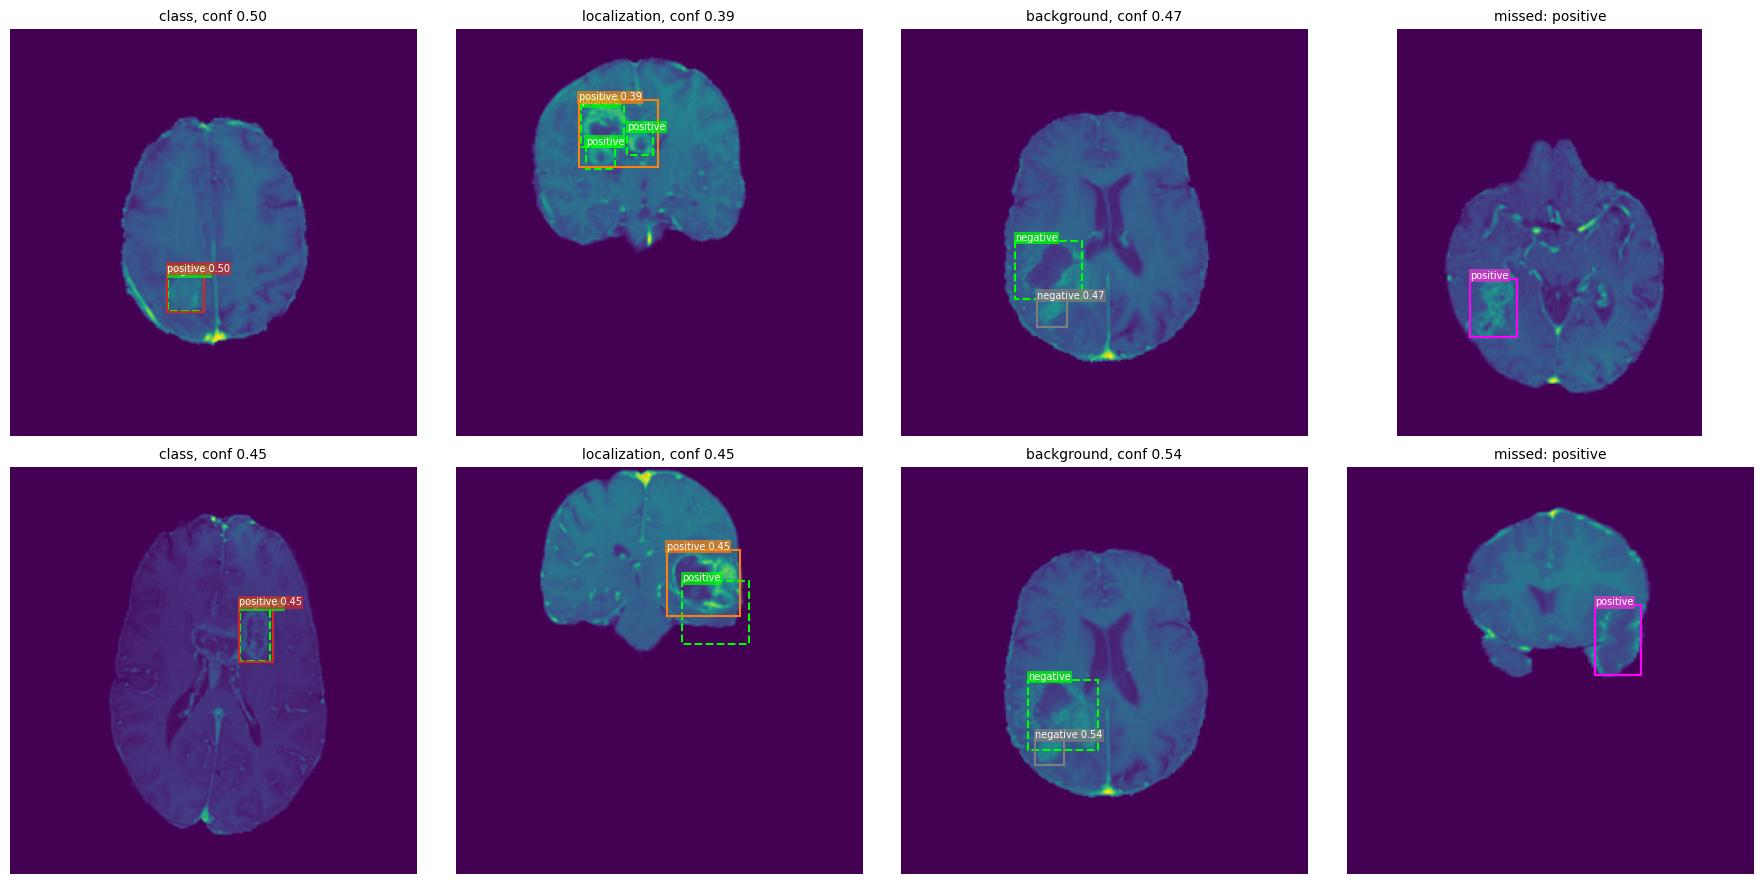

In [45]:
# ваш код
val_preds = predict_records(best, records['val'], conf=CONF_ERRORS)
ERRORS = {k: 0 for k in ERROR_TYPES}
per_class_err = {c: {k: 0 for k in ERROR_TYPES} for c in CLASSES}
examples = {k: [] for k in ERROR_TYPES}
for r, p in zip(records['val'], val_preds):
    cats, missed = categorize_predictions(p, r)
    for k, cat in enumerate(cats):
        ERRORS[cat] += 1
        per_class_err[CLASSES[int(p['labels'][k])]][cat] += 1
        if len(examples[cat]) < 2: examples[cat].append((r, p, k))
    for j in missed:
        ERRORS['missed'] += 1
        per_class_err[CLASSES[int(r['labels'][j])]]['missed'] += 1
        if len(examples['missed']) < 2: examples['missed'].append((r, p, j))
total = sum(ERRORS.values())
print('ERRORS:', ERRORS, '| доли:', {k: f'{v / total:.1%}' for k, v in ERRORS.items()})
for c, d in per_class_err.items(): print(c, d)

CAT_COLORS = {'class': 'tab:red', 'localization': 'tab:orange', 'background': 'tab:gray', 'missed': 'magenta'}
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for col, cat in enumerate(('class', 'localization', 'background', 'missed')):
    for row in range(2):
        ax = axes[row][col]
        if len(examples[cat]) <= row: ax.set_axis_off(); continue
        r, p, k = examples[cat][row]
        draw_boxes(ax, np.array(Image.open(r['image'])), r['boxes'], r['labels'], CLASSES,
                   color='lime', linestyle='--')
        if cat == 'missed':
            draw_boxes(ax, None, r['boxes'][k:k + 1], r['labels'][k:k + 1], CLASSES,
                       color='magenta', title=f'missed: {CLASSES[int(r["labels"][k])]}')
        else:
            draw_boxes(ax, None, p['boxes'][k:k + 1], p['labels'][k:k + 1], CLASSES,
                       scores=p['scores'][k:k + 1], color=CAT_COLORS[cat],
                       title=f'{cat}, conf {p["scores"][k]:.2f}')
plt.tight_layout(); plt.show()

**Ответ:** На val при conf=0.25 получены TP=115, class=62, localization=4, background=24, missed=19. Наиболее частый тип ошибки среди зарегистрированных ошибок — неверный класс: 62 из 109 (56.9%), тогда как локализационных ошибок только 4. Это говорит о том, что модель нередко находит область, но путает метку; метрику локализации независимо от класса стоило бы проверить отдельно. Категория missed в этой реализации означает GT без связи с подходящей детекцией по правилам анализа, а не все FN при стандартном подсчёте recall. Доли в таблице считаются по совокупности предсказаний и таких пропусков.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [46]:
# Сравниваем разрешения на одном и том же групповом разбиении, а не на старых логах.
ABL_IMGSZ = 320
model_abl, t_abl, dir_abl = train_yolo('abl_imgsz320', **{**TRAIN_ARGS, 'imgsz': ABL_IMGSZ})
res_abl = YOLO(dir_abl / 'weights' / 'best.pt').val(
    data=str(DATA_YAML), split='val', imgsz=ABL_IMGSZ, batch=BATCH, device=DEVICE,
    workers=WORKERS, nms=None, project=str(RUNS.resolve()), name='abl_imgsz320_val',
    exist_ok=True, verbose=False)
RUN_TIMES['ablation'] = t_abl
ABLATION = dict(param='imgsz', values=[IMGSZ, ABL_IMGSZ],
                map50=[float(res_val.box.map50), float(res_abl.box.map50)],
                map50_95=[float(res_val.box.map), float(res_abl.box.map)],
                train_time_sec=[RUN_TIMES['train'], t_abl])
print('Абляция val:', ABLATION)
print('Изменение mAP50:', f'{100 * (ABLATION["map50"][1] - ABLATION["map50"][0]):+.2f} п.п.')
print('Изменение mAP50-95:', f'{100 * (ABLATION["map50_95"][1] - ABLATION["map50_95"][0]):+.2f} п.п.')


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=abl_imgsz320, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ad

**Ответ:** При изменении imgsz с 640 до 320 val mAP50 изменился с 0.6111 до 0.6149 (+0.38 п.п.), mAP50-95 — с 0.3942 до 0.4432 (+4.90 п.п.). Время уменьшилось с 760 до 559 с (на 26.5%), хотя фактически запуски длились 52 и 60 эпох соответственно. В этом прогоне меньшее разрешение оказалось выгодным; возможно, оно снижает влияние мелких шумовых деталей, но это гипотеза, поскольку сравнение проведено с одним seed. Проверка на test варианта 320 не проводилась.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** На текущем test дообученная YOLO26n достигла mAP50=0.655 против 0 у COCO и 0.117 у яркостной эвристики. При этом mAP50-95=0.430, а recall класса positive (0.687) ниже, чем negative (0.929). На val преобладают ошибки классификации (62), а не локализации (4). Уменьшение imgsz до 320 дало mAP50-95=0.443 вместо 0.394 и сократило время на 26.5%. Самое разрушительное искажение — гауссов шум: mAP50 на val снизился с 0.611 до 0.072. Ограничения — один seed, небольшие выборки, непроверенное соответствие идентификаторов между плоскостями и отсутствие внешней клинической валидации. Дальше необходимо проверить пациентские ID, повторить обучение на гарантированно независимых группах и проверить аугментации шумом, а также отдельную одноклассовую детекцию.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [47]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value

artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES, split_strategy='patient_group_shuffle',
    split_seed=SEED, split_patient_counts={s: len(ids) for s, ids in pat.items()},
    split_patient_intersections=intersections,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])


Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [48]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [49]:
from ultralytics import RTDETR


if '6.2' in BONUS_TASKS:
    RTDETR_EPOCHS = 30
    unsupported = {'mosaic', 'close_mosaic', 'mixup', 'copy_paste', 'copy_paste_mode',
                   'multi_scale', 'erasing', 'auto_augment'}
    rtdetr_args = {k: v for k, v in TRAIN_ARGS.items() if k not in unsupported}
    rtdetr_args.update(epochs=RTDETR_EPOCHS, lr0=1e-4)

    def bench_predict_ms(model, imgsz=IMGSZ, device=DEVICE, n=15, warmup=5):
        dummy = np.zeros((imgsz, imgsz, 3), dtype=np.uint8)
        for _ in range(warmup):
            model.predict(dummy, imgsz=imgsz, device=device, verbose=False)
        ts = []
        for _ in range(n):
            if torch.cuda.is_available() and device == 0:
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            model.predict(dummy, imgsz=imgsz, device=device, verbose=False)
            if torch.cuda.is_available() and device == 0:
                torch.cuda.synchronize()
            ts.append((time.perf_counter() - t0) * 1e3)
        return float(np.mean(ts)), float(np.std(ts))

    rt_params, t_rtdetr, rtdetr_dir, rt_batch = None, None, None, None
    for bs in (4, 2):
        try:
            rtdetr = RTDETR('rtdetr-l.pt')
            rt_params = int(sum(p.numel() for p in rtdetr.model.parameters()))
            t0 = time.perf_counter()
            rtdetr.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS,
                         project=str(RUNS.resolve()), name=f'rtdetr_l_b{bs}', exist_ok=True,
                         verbose=False, **{**rtdetr_args, 'batch': bs})
            t_rtdetr = time.perf_counter() - t0
            rtdetr_dir = Path(rtdetr.trainer.save_dir)
            rt_batch = bs
            break
        except Exception as e:
            if 'out of memory' not in str(e).lower():
                raise
            print(f'batch {bs}: OOM')
            del rtdetr
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    if rtdetr_dir is None:
        raise RuntimeError('RT-DETR: не удалось обучить даже с batch=2')

    rtdetr_best = RTDETR(rtdetr_dir / 'weights' / 'best.pt')
    r_rt = rtdetr_best.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=rt_batch,
                          device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
                          name='rtdetr_l_val', exist_ok=True, verbose=False)
    lat_rt, lat_rt_sd = bench_predict_ms(rtdetr_best)
    lat_yo, lat_yo_sd = bench_predict_ms(best)
    rt_actual_epochs = len(read_results(rtdetr_dir)['epoch'])
    yo_actual_epochs = len(read_results(run_dir)['epoch'])
    RTDETR_RESULT = dict(
        weights='rtdetr-l.pt', imgsz=IMGSZ, batch=rt_batch, epochs=rt_actual_epochs,
        params=rt_params, params_yolo=int(sum(blocks.values())),
        map50=float(r_rt.box.map50), map50_95=float(r_rt.box.map),
        map50_yolo=float(res_val.box.map50), map50_95_yolo=float(res_val.box.map),
        train_time_sec=t_rtdetr, sec_per_epoch=t_rtdetr / rt_actual_epochs,
        train_time_sec_yolo=RUN_TIMES['train'], sec_per_epoch_yolo=RUN_TIMES['train'] / yo_actual_epochs,
        latency_ms=lat_rt, latency_sd_ms=lat_rt_sd, latency_ms_yolo=lat_yo,
        latency_sd_ms_yolo=lat_yo_sd, device=DEVICE_NAME)
    print(f'{"":14s} {"params":>10s} {"mAP50":>8s} {"mAP50-95":>9s} {"s/epoch":>9s} {"lat, ms":>9s}')
    for nm, p, m50, m95, spe, lt in [
        ('YOLO26n', RTDETR_RESULT['params_yolo'], RTDETR_RESULT['map50_yolo'],
         RTDETR_RESULT['map50_95_yolo'], RTDETR_RESULT['sec_per_epoch_yolo'], lat_yo),
        ('RT-DETR-l', rt_params, RTDETR_RESULT['map50'], RTDETR_RESULT['map50_95'],
         RTDETR_RESULT['sec_per_epoch'], lat_rt)]:
        print(f'{nm:14s} {p:10,d} {m50:8.3f} {m95:9.3f} {spe:9.1f} {lt:9.2f}')
    print(f'Разница RT-DETR - YOLO val mAP50: {RTDETR_RESULT["map50"] - RTDETR_RESULT["map50_yolo"]:+.4f}')
    print(f'RT-DETR: {rt_actual_epochs} эпох, batch {rt_batch}, всего {t_rtdetr:.0f} s')
    del rtdetr
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr_l_b4, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ad

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/30      3.77G      1.483     0.9922     0.7638          4        640: 100% ━━━━━━━━━━━━ 195/195 2.8it/s 1:10
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 4.4it/s 5.0s
                   all        172        182   0.000204      0.111   0.000554   9.48e-05

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/30      3.96G      1.407     0.4872     0.5104          8        640: 0% ──────────── 0/195  0.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/30      3.96G      1.018     0.9764     0.3698          4        640: 100% ━━━━━━━━━━━━ 195/195 3.0it/s 1:05
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 5.5it/s 4.0s
                   all        172        182    0.00476      0.928     0.0336    0.00851

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/30      3.96G     0.7386      1.222     0.1894         10        640: 0% ──────────── 0/195  0.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (51 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      29/30      3.96G     0.2865     0.6153     0.1136          2        640: 100% ━━━━━━━━━━━━ 195/195 3.0it/s 1:06
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 5.6it/s 3.9s
                   all        172        182      0.452      0.845      0.508      0.334

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      30/30      3.96G     0.2406       0.59    0.08566          4        640: 0% ──────────── 0/195  0.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      30/30      3.96G     0.2944     0.6174     0.1179          2        640: 100% ━━━━━━━━━━━━ 195/195 2.9it/s 1:06
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 5.7it/s 3.9s
                   all        172        182      0.452      0.845      0.507      0.335

30 epochs completed in 0.710 hours.
Optimizer stripped from /content/runs_hw2/rtdetr_l_b4/weights/last.pt, 66.2MB
Optimizer stripped from /content/runs_hw2/rtdetr_l_b4/weights/best.pt, 66.2MB

Validating /content/runs_hw2/rtdetr_l_b4/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 31,987,850 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 5.6it/s 3.9s
                   all        172        182      0.451      0.845      0.507      0.332
Speed: 0.6ms preprocess,

**Ответ:** На одном val RT-DETR-L получил mAP50=0.506 и mAP50-95=0.334 против 0.611/0.394 у YOLO26n. RT-DETR-L содержит 32.97 млн параметров против 2.57 млн, обучался 2570 с за 30 эпох (85.7 с/эпоху) против 760 с за 52 эпохи YOLO (14.6 с/эпоху), а задержка на T4 составляет 43.22 против 10.88 мс. YOLO предпочтительнее в данном бюджете; RT-DETR стоило бы рассматривать, если при дополнительном подборе гиперпараметров и большем бюджете он даст лучшее качество, но здесь это не подтверждено. Сравнение ограничено разными batch, числом эпох и настройками обучения.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [ ]:
if '6.3' in BONUS_TASKS:
    rng_shift = np.random.default_rng(SEED)

    def save_dark(im, p):
        Image.fromarray((np.asarray(im, np.float32) * 0.5).clip(0, 255).astype(np.uint8)).save(p)

    def save_noise(im, p):
        a = np.asarray(im, np.float32)
        Image.fromarray((a + rng_shift.normal(0, 20, a.shape)).clip(0, 255).astype(np.uint8)).save(p)

    def save_jpeg(im, p):
        im.save(p, format='JPEG', quality=10)

    SHIFTS = {'val_dark': save_dark, 'val_noise': save_noise, 'val_jpeg10': save_jpeg}
    for name, fn in SHIFTS.items():
        idir, ldir = YOLO_ROOT / 'images' / name, YOLO_ROOT / 'labels' / name
        shutil.rmtree(idir, ignore_errors=True)
        shutil.rmtree(ldir, ignore_errors=True)
        idir.mkdir(parents=True, exist_ok=True)
        ldir.mkdir(parents=True, exist_ok=True)
        for r in records['val']:
            src_name = yolo_name(r)
            ext = '.jpg' if name == 'val_jpeg10' else '.png'
            dst_name = Path(src_name).with_suffix(ext).name
            with Image.open(r['image']) as im:
                fn(im.convert('RGB'), idir / dst_name)
            shutil.copy(YOLO_ROOT / 'labels' / 'val' / (Path(src_name).stem + '.txt'),
                        ldir / (Path(dst_name).stem + '.txt'))

    DATA_SHIFT_YAML = YOLO_ROOT / 'data_shifts.yaml'
    data_shift = {'path': YOLO_ROOT.resolve().as_posix(),
                  **{s: (YOLO_ROOT / 'images' / s).resolve().as_posix()
                     for s in list(splits) + list(SHIFTS)},
                  'names': {i: n for i, n in enumerate(CLASSES)}}
    DATA_SHIFT_YAML.write_text(yaml.safe_dump(data_shift, allow_unicode=True, sort_keys=False), encoding='utf-8')
    print('Для доменных сдвигов создан отдельный', DATA_SHIFT_YAML)
    SHIFT_RESULTS = {'val_clean': (float(res_val.box.map50), float(res_val.box.map))}
    for name in SHIFTS:
        m = val_metrics(best, name, f'shift_{name}', data_yaml=DATA_SHIFT_YAML, nms=None)
        SHIFT_RESULTS[name] = (float(m.box.map50), float(m.box.map))
        print(name, 'mAP50', round(m.box.map50, 4), 'mAP50-95', round(m.box.map, 4),
              {m.names[int(c)]: round(float(m.box.ap50[i]), 3) for i, c in enumerate(m.box.ap_class_index)})
    for name in SHIFTS:
        print(f'{name}: изменение mAP50 = {SHIFT_RESULTS[name][0] - SHIFT_RESULTS["val_clean"][0]:+.4f}')


Для доменных сдвигов создан отдельный data/yolo/data_shifts.yaml
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 510.5±252.5 MB/s, size: 18.4 KB)
val: Scanning /content/data/yolo/labels/val_dark... 172 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 172/172 2.0Kit/s 0.1s
val: New cache created: /content/data/yolo/labels/val_dark.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 3.4it/s 3.2s
                   all        172        182      0.495      0.763      0.611      0.404
Speed: 2.7ms preprocess, 4.7ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/runs_hw2/shift_val_dark
val_dark mAP50 0.6108 mAP50-95 0.4037 {'negative': 0.631, 'positive': 0.59}
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Te

**Ответ:** На исходном val mAP50/mAP50-95=0.6111/0.3942, при затемнении — 0.6108/0.4037, шуме — 0.0718/0.0468, JPEG quality=10 — 0.3974/0.2504. Сильнее всего влияет гауссов шум (σ=20 из 255): падение mAP50 на 53.94 п.п., AP50 negative=0.035 и positive=0.109; JPEG также заметно ухудшает качество (AP50 negative=0.467, positive=0.327). Затемнение практически не повлияло на mAP50. Можно попробовать аугментации гауссовым шумом, JPEG-компрессией и изменением контраста на train с проверкой качества на чистом и искажённом val.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [ ]:
if '6.4' in BONUS_TASKS:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnx', 'onnxruntime', 'onnxslim'], check=True)
    import onnx
    import onnxruntime as ort

    onnx_path = Path(best.export(format='onnx', imgsz=IMGSZ, simplify=True,
                                 dynamic=False, device='cpu', nms=None))
    graph = onnx.load(str(onnx_path))
    onnx.checker.check_model(graph)
    print('ONNX ok:', onnx_path.name, f'{onnx_path.stat().st_size / 2**20:.2f} МиБ',
          '| входы:', [(i.name, [d.dim_value for d in i.type.tensor_type.shape.dim]) for i in graph.graph.input],
          '| выходы:', [(o.name, [d.dim_value for d in o.type.tensor_type.shape.dim]) for o in graph.graph.output])

    with Image.open(records['val'][0]['image']) as im:
        img = np.asarray(im.convert('RGB').resize((IMGSZ, IMGSZ)), dtype=np.float32)
    x = np.ascontiguousarray(img.transpose(2, 0, 1)[None] / 255.0)
    K = 4

    def bench_forward(fn, n=30, warmup=5):
        for _ in range(warmup):
            fn()
        ts = []
        for _ in range(n):
            t0 = time.perf_counter()
            fn()
            ts.append((time.perf_counter() - t0) * 1e3)
        return float(np.median(ts)), float(np.std(ts))

    old_threads = torch.get_num_threads()
    torch.set_num_threads(K)
    try:
        pt_cpu = YOLO(run_dir / 'weights' / 'best.pt')
        pt_cpu.model.fuse(verbose=False)
        pt_cpu.model.end2end = False
        pt_cpu.model.eval().float().cpu()
        xt = torch.from_numpy(x)
        with torch.inference_mode():
            lat_pt_cpu, sd_pt_cpu = bench_forward(lambda: pt_cpu.model(xt))

        so = ort.SessionOptions()
        so.intra_op_num_threads = K
        so.inter_op_num_threads = 1
        so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
        sess = ort.InferenceSession(str(onnx_path), sess_options=so, providers=['CPUExecutionProvider'])
        iname = sess.get_inputs()[0].name
        with torch.inference_mode():
            pt_raw = pt_cpu.model(xt)
        if isinstance(pt_raw, (tuple, list)):
            pt_raw = pt_raw[0]
        onnx_raw = sess.run(None, {iname: x})[0]
        print('PyTorch raw:', tuple(pt_raw.shape), 'ONNX raw:', tuple(onnx_raw.shape))
        assert tuple(pt_raw.shape) == tuple(onnx_raw.shape), (pt_raw.shape, onnx_raw.shape)
        print('Raw abs max error:', np.max(np.abs(pt_raw.detach().cpu().numpy() - onnx_raw)))
        lat_ort_cpu, sd_ort_cpu = bench_forward(lambda: sess.run(None, {iname: x}))
    finally:
        torch.set_num_threads(old_threads)

    res_pt_cpu = pt_cpu.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1,
                            device='cpu', workers=WORKERS, half=False, nms=None,
                            project=str(RUNS.resolve()), name='pt_cpu_val', exist_ok=True, verbose=False)
    onnx_model = YOLO(str(onnx_path), task='detect')
    res_onnx = onnx_model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1,
                              device='cpu', workers=WORKERS, half=False, nms=None,
                              project=str(RUNS.resolve()), name='onnx_val', exist_ok=True, verbose=False)
    ONNX_RESULT = dict(
        file=onnx_path.name, size_mb=onnx_path.stat().st_size / 2**20,
        size_mb_pt=(run_dir / 'weights' / 'best.pt').stat().st_size / 2**20,
        threads=K, imgsz=IMGSZ, timing='median forward CPU fp32, batch=1',
        latency_cpu_torch_ms=lat_pt_cpu, latency_cpu_onnx_ms=lat_ort_cpu,
        std_cpu_torch_ms=sd_pt_cpu, std_cpu_onnx_ms=sd_ort_cpu,
        speedup_cpu=lat_pt_cpu / lat_ort_cpu,
        map50_pt=float(res_pt_cpu.box.map50), map50_onnx=float(res_onnx.box.map50),
        map50_95_pt=float(res_pt_cpu.box.map), map50_95_onnx=float(res_onnx.box.map))
    print(f'CPU torch (fp32, {K} потока): медиана {lat_pt_cpu:.2f} мс (sd {sd_pt_cpu:.2f})')
    print(f'CPU ONNX  (fp32, {K} потока): медиана {lat_ort_cpu:.2f} мс (sd {sd_ort_cpu:.2f}),'
          f' speedup x{lat_pt_cpu / lat_ort_cpu:.2f}')
    print(f'mAP50 CPU fp32: pt={res_pt_cpu.box.map50:.4f}, onnx={res_onnx.box.map50:.4f}')
    print(f'mAP50-95 CPU fp32: pt={res_pt_cpu.box.map:.4f}, onnx={res_onnx.box.map:.4f}')


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.0s, saved as '/content/runs_hw2/finetune/weights/best.onnx' (9.4 MB)

Export complete (2.5s)
Results saved to /content/runs_hw2/finetune/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs_hw2/finetune/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs_hw2/finetune/weights/best.onnx imgsz=640 data=data/yolo/data.yaml 
Visualize:       https://netron.app
ONN

**Ответ:** Экспорт ONNX выполнен со статическим входом 1×3×640×640, fp32; формы сырых выходов совпали (1, 6, 8400), максимальная абсолютная разница в проверенном примере — 0.00183. На CPU с 4 потоками медиана forward PyTorch=169.87 мс, ONNX=188.97 мс, ускорение x0.90 (примерно на 11% медленнее по медиане, при большом разбросе ONNX). mAP50 практически сохранился (0.6100→0.6103), но mAP50-95 снизился с 0.3956 до 0.3662, что требует отдельной проверки различий препроцессинга и постпроцессинга. В этом эксперименте переход на ONNX не дал выигрыша в скорости.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [ ]:
if '6.5' in BONUS_TASKS:
    THRESHOLDS = []
    for nms in (False, True):
        mode = 'one_to_one_no_nms' if nms is False else 'one_to_many_nms'
        for conf in (0.001, 0.1, 0.25, 0.5):
            for iou in (0.3, 0.7):
                m = best.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH,
                             device=DEVICE, workers=WORKERS, conf=conf, iou=iou, nms=nms,
                             project=str(RUNS.resolve()), name=f'thr_{mode}_c{conf}_i{iou}',
                             exist_ok=True, verbose=False, plots=False)
                preds_at_conf = predict_records(best, records['val'], conf=conf, iou=iou, nms=nms)
                fixed = precision_recall_at_conf(preds_at_conf, records['val'])
                row = dict(mode=mode, nms=nms, conf=conf, iou=iou,
                           precision_at_conf=round(fixed['precision'], 4),
                           recall_at_conf=round(fixed['recall'], 4),
                           tp=fixed['tp'], fp=fixed['fp'], fn=fixed['fn'],
                           P_ultralytics=round(float(m.box.mp), 4),
                           R_ultralytics=round(float(m.box.mr), 4),
                           map50=round(float(m.box.map50), 4),
                           map50_95=round(float(m.box.map), 4))
                THRESHOLDS.append(row)
                print(row)
    for nms in (False, True):
        rows = [r for r in THRESHOLDS if r['nms'] is nms]
        max_iou_effect = max(abs(next(r for r in rows if r['conf'] == conf and r['iou'] == 0.3)['map50'] -
                                 next(r for r in rows if r['conf'] == conf and r['iou'] == 0.7)['map50'])
                             for conf in (0.001, 0.1, 0.25, 0.5))
        print(f'nms={nms}: max |ΔmAP50| при смене iou = {max_iou_effect:.4f}')
    probe = [str(r['image']) for r in records['val'][:3]]
    p_one = best.predict(probe, conf=0.001, iou=0.7, nms=False, imgsz=IMGSZ, device=DEVICE, verbose=False)
    p_many = best.predict(probe, conf=0.001, iou=0.7, nms=True, imgsz=IMGSZ, device=DEVICE, verbose=False)
    def signature(res):
        bb = res.boxes.cpu()
        return np.column_stack([bb.xyxy.numpy(), bb.conf.numpy(), bb.cls.numpy()])
    different = any((a.shape != b.shape) or not np.allclose(a, b, atol=1e-4)
                    for a, b in zip(map(signature, p_one), map(signature, p_many)))
    print('Разные предсказания при nms=False и nms=True:', different)
    if not different:
        print('Режимы не различились на 3 изображениях')


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 375.4±69.6 MB/s, size: 11.9 KB)
val: Scanning /content/data/yolo/labels/val.cache... 172 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 172/172 45.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 5.6it/s 2.0s
                   all        172        182      0.495       0.72      0.575      0.363
Speed: 1.4ms preprocess, 4.3ms inference, 0.0ms loss, 0.3ms postprocess per image
{'mode': 'one_to_one_no_nms', 'nms': False, 'conf': 0.001, 'iou': 0.3, 'precision_at_conf': 0.1489, 'recall_at_conf': 0.9615, 'tp': 175, 'fp': 1000, 'fn': 7, 'P_ultralytics': 0.4946, 'R_ultralytics': 0.72, 'map50': 0.5749, 'map50_95': 0.3626}
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 1491

In [53]:
bonus = {k: v for k, v in [('rtdetr', globals().get('RTDETR_RESULT')),
                           ('domain_shift', globals().get('SHIFT_RESULTS')),
                           ('onnx', globals().get('ONNX_RESULT')),
                           ('thresholds', globals().get('THRESHOLDS'))] if v is not None}
if bonus:
    (artifact_dir / 'bonus.json').write_text(
        json.dumps(json_ready(bonus), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    print('bonus.json:', list(bonus))

bonus.json: ['rtdetr', 'domain_shift', 'onnx', 'thresholds']


**Ответ:** В one-to-one при nms=False изменение IoU 0.3→0.7 не изменило mAP50, при nms=True максимальная разница составила 0.008; предсказания двух веток различаются. При nms=True, iou=0.3 рост conf с 0.001 до 0.5 увеличил precision с 0.331 до 0.635 и снизил recall с 0.742 до 0.506. Для учебного сценария, где пропуск объекта нежелателен, разумная отправная точка — nms=False, conf=0.1 (micro precision=0.433, recall=0.769), хотя конкретный порог зависит от допустимого числа FP и не является клинической рекомендацией. mAP агрегирует PR-кривую, но большой conf отсекает её часть: без NMS mAP50 снижается с 0.5749 при conf=0.001 до 0.2822 при 0.5. Поэтому для стандартного сравнения AP нужен низкий conf, а для рабочего порога — P/R при фиксированном conf.